# PCA on Car Dataset — With vs. Without `model_cat`

**Math 17 Final Project**

This notebook runs two parallel PCA analyses on the cleaned car dataset:

- **Version A — Without `model_cat`**: numeric features + 6 categorical features (excluding the 669-level `model_cat`). This produces a clean, interpretable PCA.
- **Version B — With `model_cat`**: same as above plus one-hot encoded `model_cat`. This explores what happens when we include high-cardinality categoricals.

We then compare the two side by side.



## 1. Setup

In [7]:
# If running in Colab, uncomment to install packages:
!pip install numpy pandas scikit-learn matplotlib seaborn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)
np.random.seed(42)

### Loading the dataset

In [8]:
DATA_PATH = "cleanedupcardataupdated_colors.csv"  # adjust if needed

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (642976, 12)


,year,mileage,exterior_color,interior_color,accidents_or_damage,one_owner,price,manufacturer_cat,model_cat,transmission_cat,drivetrain_cat,fuel_type_cat
0,2013,92945.0,Black,Beige,0,0,13988,Acura,ILX,automatic,2WD,gasoline
1,2013,47645.0,Gray,Black,1,1,17995,Acura,ILX,automatic,2WD,hybrid
2,2013,53422.0,White,Black,0,1,17000,Acura,ILX,automatic,2WD,hybrid
3,2013,62042.0,Silver,Black,0,0,18000,Acura,ILX,automatic,2WD,hybrid
4,2013,57212.0,Silver,Black,0,1,15999,Acura,ILX,automatic,2WD,hybrid


In [9]:
# Quick sanity check on columns and dtypes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 642976 entries, 0 to 642975
Data columns (total 12 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   year                 642976 non-null  int64  
 1   mileage              642649 non-null  float64
 2   exterior_color       642883 non-null  object 
 3   interior_color       642855 non-null  object 
 4   accidents_or_damage  642976 non-null  int64  
 5   one_owner            642976 non-null  int64  
 6   price                642976 non-null  int64  
 7   manufacturer_cat     642976 non-null  object 
 8   model_cat            642976 non-null  object 
 9   transmission_cat     642976 non-null  object 
 10  drivetrain_cat       642976 non-null  object 
 11  fuel_type_cat        642976 non-null  object 
dtypes: float64(1), int64(4), object(7)
memory usage: 58.9+ MB


In [10]:
# Sample down to 300k rows so Version B fits in Colab's RAM.
# PCA results are very stable at this size — the loadings barely move vs. the full 643k.
df = df.sample(n=300_000, random_state=42).reset_index(drop=True)
print("Sampled shape:", df.shape)

Sampled shape: (300000, 12)


## 2. Data Preparation

We separate `price` (the eventual regression target) from the predictors. PCA is run on the predictors only. We'll use `price` later to color the PC scatter plot. We also drop any rows with missing values to keep things simple.

In [11]:
# Drop missing values (simple approach)
df = df.dropna().reset_index(drop=True)
print("After dropna:", df.shape)

# Target
y = df["price"].values

# Define column groups
numeric_cols = ["year", "mileage", "accidents_or_damage", "one_owner"]

categorical_cols_no_model = [
    "exterior_color",
    "interior_color",
    "manufacturer_cat",
    "transmission_cat",
    "drivetrain_cat",
    "fuel_type_cat",
]

categorical_cols_with_model = categorical_cols_no_model + ["model_cat"]

print("Numeric features:", numeric_cols)
print("Categorical (no model):", categorical_cols_no_model)
print("Categorical (with model):", categorical_cols_with_model)

After dropna: (299748, 12)
Numeric features: ['year', 'mileage', 'accidents_or_damage', 'one_owner']
Categorical (no model): ['exterior_color', 'interior_color', 'manufacturer_cat', 'transmission_cat', 'drivetrain_cat', 'fuel_type_cat']
Categorical (with model): ['exterior_color', 'interior_color', 'manufacturer_cat', 'transmission_cat', 'drivetrain_cat', 'fuel_type_cat', 'model_cat']


In [12]:
# Cardinality check — useful context for interpreting results later
for col in categorical_cols_with_model:
    print(f"{col}: {df[col].nunique()} unique values")

exterior_color: 13 unique values
interior_color: 13 unique values
manufacturer_cat: 30 unique values
transmission_cat: 2 unique values
drivetrain_cat: 2 unique values
fuel_type_cat: 5 unique values
model_cat: 645 unique values


## 3. Helper function

We'll run essentially the same pipeline twice. This helper builds the feature matrix, standardizes it, and fits PCA. Returns the fitted PCA object, the transformed scores, and the column names of the feature matrix (needed to interpret loadings).

In [13]:
def build_and_fit_pca(df, numeric_cols, categorical_cols, n_components=None):
    """One-hot encode categoricals, standardize all features, fit PCA.

    Returns
    -------
    pca : fitted sklearn PCA object
    scores : ndarray of shape (n_samples, n_components) — PC scores
    feature_names : list of column names in the design matrix (post one-hot)
    X_scaled : the standardized design matrix (useful for diagnostics)
    """
    # Numeric block
    X_num = df[numeric_cols].astype(float)

    # Categorical block — one-hot encode (drop_first=False keeps all dummies;
    # set to True if you want to avoid the dummy-variable trap)
    X_cat = pd.get_dummies(df[categorical_cols], drop_first=False)

    # Combine
    X = pd.concat([X_num.reset_index(drop=True), X_cat.reset_index(drop=True)], axis=1)
    feature_names = X.columns.tolist()

    # Standardize: mean 0, variance 1 for every column
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X.values)

    # Fit PCA
    pca = PCA(n_components=n_components, random_state=42)
    scores = pca.fit_transform(X_scaled)

    return pca, scores, feature_names, X_scaled

## 4. Version A — PCA **without** `model_cat`

Feature matrix: 4 numeric + ~65 one-hot columns from 6 categoricals.

In [14]:
pca_A, scores_A, features_A, X_A = build_and_fit_pca(
    df,
    numeric_cols=numeric_cols,
    categorical_cols=categorical_cols_no_model,
)

print("Design matrix shape:", X_A.shape)
print("Number of components fit:", pca_A.n_components_)

Design matrix shape: (299748, 69)
Number of components fit: 69


### 4a. Scree plot — Version A

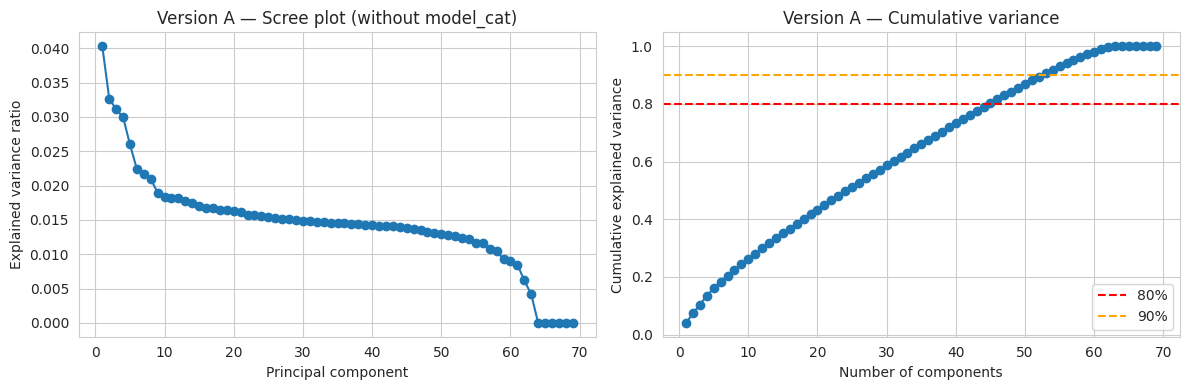

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Explained variance ratio per component
axes[0].plot(np.arange(1, len(pca_A.explained_variance_ratio_) + 1),
             pca_A.explained_variance_ratio_, marker="o")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Explained variance ratio")
axes[0].set_title("Version A — Scree plot (without model_cat)")

# Cumulative explained variance
axes[1].plot(np.arange(1, len(pca_A.explained_variance_ratio_) + 1),
             np.cumsum(pca_A.explained_variance_ratio_), marker="o")
axes[1].axhline(0.8, color="red", linestyle="--", label="80%")
axes[1].axhline(0.9, color="orange", linestyle="--", label="90%")
axes[1].set_xlabel("Number of components")
axes[1].set_ylabel("Cumulative explained variance")
axes[1].set_title("Version A — Cumulative variance")
axes[1].legend()

plt.tight_layout()
plt.show()

In [16]:
# How many components to reach 80% / 90% variance?
cum_A = np.cumsum(pca_A.explained_variance_ratio_)
print(f"Version A — components for 80% variance: {(cum_A < 0.8).sum() + 1}")
print(f"Version A — components for 90% variance: {(cum_A < 0.9).sum() + 1}")
print(f"Version A — PC1 explains: {pca_A.explained_variance_ratio_[0]:.3%}")
print(f"Version A — PC1+PC2 explain: {pca_A.explained_variance_ratio_[:2].sum():.3%}")

Version A — components for 80% variance: 45
Version A — components for 90% variance: 53
Version A — PC1 explains: 4.029%
Version A — PC1+PC2 explain: 7.296%


### 4b. Loadings — Version A

For each of the top components, show the features with the largest absolute loading. This is to interpret what each PC "means".

In [17]:
def top_loadings(pca, feature_names, pc_index, n=10):
    """Return a DataFrame of the top-n features (by |loading|) for one PC."""
    loadings = pca.components_[pc_index]
    s = pd.Series(loadings, index=feature_names)
    s_sorted = s.reindex(s.abs().sort_values(ascending=False).index)
    return s_sorted.head(n).to_frame(f"PC{pc_index + 1} loading")

print("=== Version A: top loadings for PC1, PC2, PC3 ===\n")
for i in range(3):
    print(top_loadings(pca_A, features_A, i, n=10))
    print()

=== Version A: top loadings for PC1, PC2, PC3 ===

                            PC1 loading
drivetrain_cat_4WD            -0.420871
drivetrain_cat_2WD             0.420871
year                          -0.369906
mileage                        0.322971
one_owner                     -0.242538
interior_color_Black          -0.226274
interior_color_Gray            0.224462
transmission_cat_automatic    -0.177753
transmission_cat_manual        0.177753
accidents_or_damage            0.170257

                            PC2 loading
fuel_type_cat_gasoline         0.445702
transmission_cat_automatic    -0.403266
transmission_cat_manual        0.403266
interior_color_Black           0.267775
fuel_type_cat_hybrid          -0.227653
fuel_type_cat_diesel          -0.221377
fuel_type_cat_e85             -0.203638
fuel_type_cat_electric        -0.196775
interior_color_Gray           -0.172658
manufacturer_cat_Tesla        -0.155321

                            PC3 loading
year                       

### 4c. PC1 vs PC2 scatter — Version A

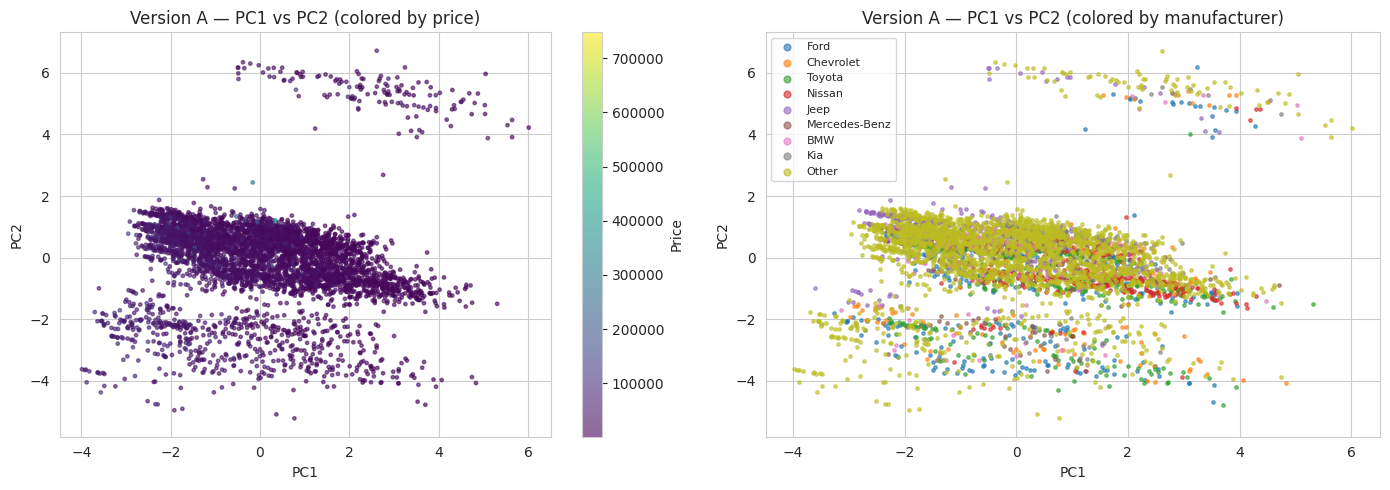

In [18]:
# Plot a sample to keep rendering fast (643k points is too many)
SAMPLE = 5000
idx = np.random.choice(len(scores_A), size=min(SAMPLE, len(scores_A)), replace=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Colored by price
sc0 = axes[0].scatter(scores_A[idx, 0], scores_A[idx, 1], c=y[idx],
                      cmap="viridis", s=6, alpha=0.6)
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].set_title("Version A — PC1 vs PC2 (colored by price)")
plt.colorbar(sc0, ax=axes[0], label="Price")

# Colored by manufacturer (top 8 manufacturers, rest grouped)
top_mfrs = df["manufacturer_cat"].value_counts().head(8).index
mfr_label = df["manufacturer_cat"].where(df["manufacturer_cat"].isin(top_mfrs), "Other")
for mfr in list(top_mfrs) + ["Other"]:
    mask = (mfr_label.iloc[idx].values == mfr)
    axes[1].scatter(scores_A[idx][mask, 0], scores_A[idx][mask, 1],
                    s=6, alpha=0.6, label=mfr)
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].set_title("Version A — PC1 vs PC2 (colored by manufacturer)")
axes[1].legend(markerscale=2, fontsize=8, loc="best")

plt.tight_layout()
plt.show()

## 5. Version B — PCA **with** `model_cat`

Feature matrix: 4 numeric + ~734 one-hot columns. This is the high-cardinality version.

In [19]:


pca_B, scores_B, features_B, X_B = build_and_fit_pca(
    df,
    numeric_cols=numeric_cols,
    categorical_cols=categorical_cols_with_model,
    n_components=50,  # cap components for speed — we only need the top ones anyway
)

print("Design matrix shape:", X_B.shape)
print("Number of components fit:", pca_B.n_components_)

Design matrix shape: (299748, 714)
Number of components fit: 50


### 5a. Scree plot — Version B

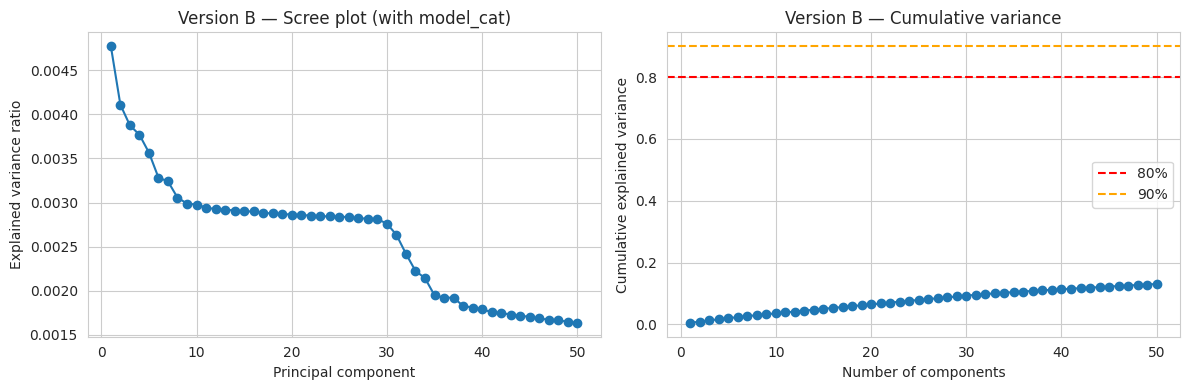

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(np.arange(1, len(pca_B.explained_variance_ratio_) + 1),
             pca_B.explained_variance_ratio_, marker="o")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Explained variance ratio")
axes[0].set_title("Version B — Scree plot (with model_cat)")

axes[1].plot(np.arange(1, len(pca_B.explained_variance_ratio_) + 1),
             np.cumsum(pca_B.explained_variance_ratio_), marker="o")
axes[1].axhline(0.8, color="red", linestyle="--", label="80%")
axes[1].axhline(0.9, color="orange", linestyle="--", label="90%")
axes[1].set_xlabel("Number of components")
axes[1].set_ylabel("Cumulative explained variance")
axes[1].set_title("Version B — Cumulative variance")
axes[1].legend()

plt.tight_layout()
plt.show()

In [21]:
cum_B = np.cumsum(pca_B.explained_variance_ratio_)
print(f"Version B — PC1 explains: {pca_B.explained_variance_ratio_[0]:.3%}")
print(f"Version B — PC1+PC2 explain: {pca_B.explained_variance_ratio_[:2].sum():.3%}")
print(f"Version B — top 50 components explain: {cum_B[-1]:.3%}")
print("(Note: we only computed 50 components for speed; the full decomposition would have ~738.)")

Version B — PC1 explains: 0.477%
Version B — PC1+PC2 explain: 0.888%
Version B — top 50 components explain: 13.056%
(Note: we only computed 50 components for speed; the full decomposition would have ~738.)


### 5b. Loadings — Version B


In [22]:
print("=== Version B: top loadings for PC1, PC2, PC3 ===\n")
for i in range(3):
    print(top_loadings(pca_B, features_B, i, n=10))
    print()

=== Version B: top loadings for PC1, PC2, PC3 ===

                         PC1 loading
drivetrain_cat_4WD          0.418309
drivetrain_cat_2WD         -0.418309
year                        0.247954
mileage                    -0.206615
interior_color_Gray        -0.203912
interior_color_Black        0.177822
fuel_type_cat_diesel        0.155067
one_owner                   0.147746
manufacturer_cat_Nissan    -0.141219
manufacturer_cat_RAM        0.118569

                            PC2 loading
fuel_type_cat_gasoline         0.452404
fuel_type_cat_electric        -0.341065
manufacturer_cat_Tesla        -0.304039
model_cat_Model               -0.304039
fuel_type_cat_diesel          -0.203292
fuel_type_cat_hybrid          -0.197008
transmission_cat_automatic    -0.163356
transmission_cat_manual        0.163356
manufacturer_cat_Subaru        0.148138
fuel_type_cat_e85             -0.145476

                            PC3 loading
interior_color_Black           0.365699
transmission_cat_man

### 5c. PC1 vs PC2 scatter — Version B

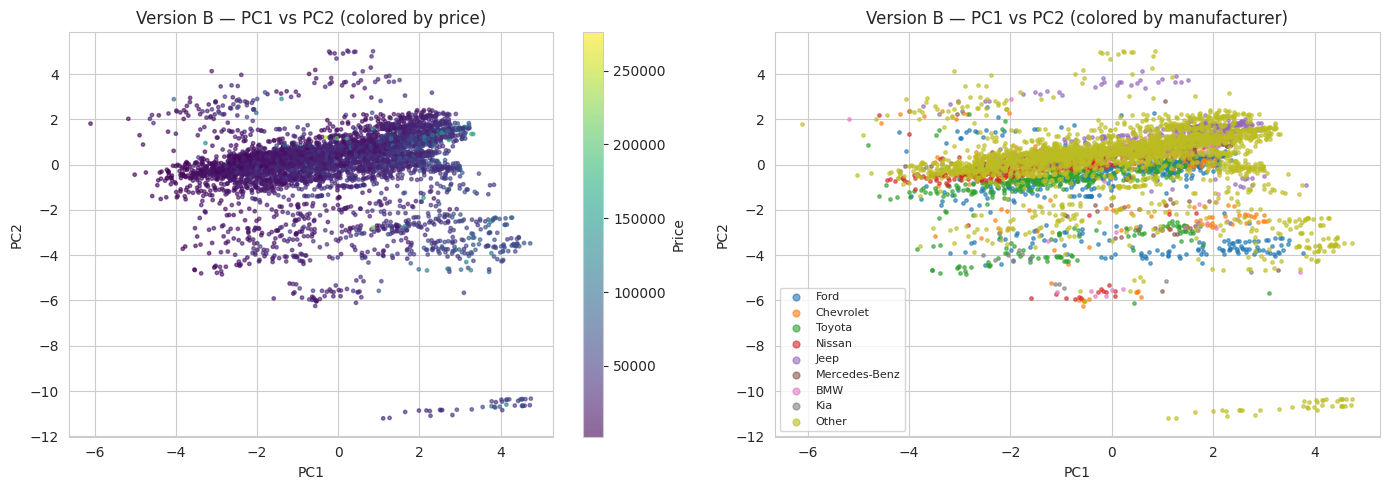

In [23]:
idx_B = np.random.choice(len(scores_B), size=min(SAMPLE, len(scores_B)), replace=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sc0 = axes[0].scatter(scores_B[idx_B, 0], scores_B[idx_B, 1], c=y[idx_B],
                      cmap="viridis", s=6, alpha=0.6)
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].set_title("Version B — PC1 vs PC2 (colored by price)")
plt.colorbar(sc0, ax=axes[0], label="Price")

for mfr in list(top_mfrs) + ["Other"]:
    mask = (mfr_label.iloc[idx_B].values == mfr)
    axes[1].scatter(scores_B[idx_B][mask, 0], scores_B[idx_B][mask, 1],
                    s=6, alpha=0.6, label=mfr)
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].set_title("Version B — PC1 vs PC2 (colored by manufacturer)")
axes[1].legend(markerscale=2, fontsize=8, loc="best")

plt.tight_layout()
plt.show()

## 6. Side-by-side comparison



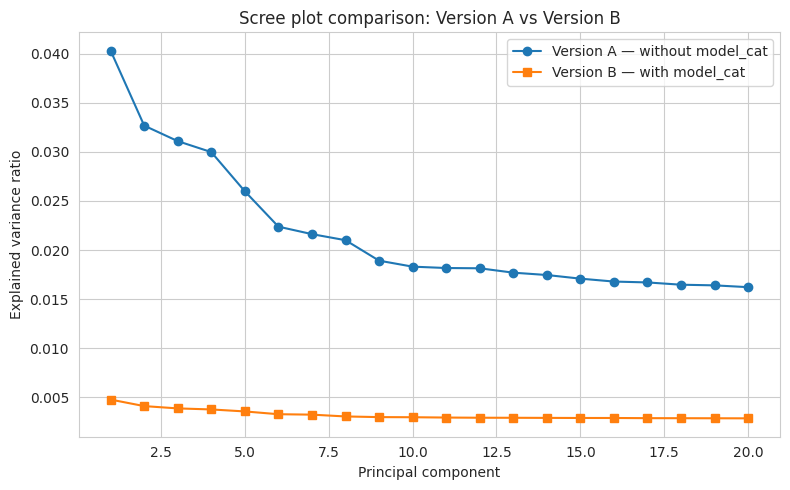

In [24]:
fig, ax = plt.subplots(figsize=(8, 5))

n_show = min(20, len(pca_A.explained_variance_ratio_), len(pca_B.explained_variance_ratio_))

ax.plot(np.arange(1, n_show + 1), pca_A.explained_variance_ratio_[:n_show],
        marker="o", label="Version A — without model_cat")
ax.plot(np.arange(1, n_show + 1), pca_B.explained_variance_ratio_[:n_show],
        marker="s", label="Version B — with model_cat")
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax.set_title("Scree plot comparison: Version A vs Version B")
ax.legend()

plt.tight_layout()
plt.show()

In [25]:
# Numeric comparison table
comparison = pd.DataFrame({
    "Metric": [
        "Design matrix columns",
        "PC1 explained variance",
        "PC1 + PC2 explained variance",
        "PC1 + PC2 + PC3 explained variance",
        "Components to reach 80% variance",
    ],
    "Version A (no model_cat)": [
        X_A.shape[1],
        f"{pca_A.explained_variance_ratio_[0]:.3%}",
        f"{pca_A.explained_variance_ratio_[:2].sum():.3%}",
        f"{pca_A.explained_variance_ratio_[:3].sum():.3%}",
        (cum_A < 0.8).sum() + 1,
    ],
    "Version B (with model_cat)": [
        X_B.shape[1],
        f"{pca_B.explained_variance_ratio_[0]:.3%}",
        f"{pca_B.explained_variance_ratio_[:2].sum():.3%}",
        f"{pca_B.explained_variance_ratio_[:3].sum():.3%}",
        (cum_B < 0.8).sum() + 1 if (cum_B >= 0.8).any() else f">{len(cum_B)} (not reached in top 50)",
    ],
})
comparison

,Metric,Version A (no model_cat),Version B (with model_cat)
0,Design matrix columns,69,714
1,PC1 explained variance,4.029%,0.477%
2,PC1 + PC2 explained variance,7.296%,0.888%
3,PC1 + PC2 + PC3 explained variance,10.404%,1.276%
4,Components to reach 80% variance,45,>50 (not reached in top 50)
